In [3]:
%pip install kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 KB 1.4 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 KB 70.8 kB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [36]:
import sys
sys.path.insert(0,"workspace")
from src.data_leader import load_data
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

train_ds , test_ds , val_ds = load_data()
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Récupérer les labels du dataset d'entraînement
y_train = np.concatenate([
    labels.numpy().ravel()
    for images, labels in train_ds
])

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)
base_model = MobileNetV2(weights="imagenet",include_top=False,input_shape=(224,224,3))
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomZoom(
        height_factor=0.5,
        width_factor=0.5
    )
])

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224,224,3)),
    data_augmentation,
    tf.keras.layers.Lambda(preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1,activation="sigmoid")

])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", "recall", "precision"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights
)

result = model.evaluate(test_ds , return_dict=True)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Class weights: {0: 1.9107142857142858, 1: 0.6772151898734177}
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8758 - loss: 0.2821 - precision: 0.9561 - recall: 0.8681 - val_accuracy: 0.7147 - val_loss: 4.9771 - val_precision: 0.6866 - val_recall: 1.0000
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.9299 - loss: 0.1909 - precision: 0.9815 - recall: 0.9218 - val_accuracy: 0.8894 - val_loss: 0.8468 - val_precision: 0.8512 - val_recall: 0.9974
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.9483 - loss: 0.1325 - precision: 0.9852 - recall: 0.9435 - val_accuracy: 0.8237 - val_loss: 1.8522 - val_precision: 0.7800 - val_recall: 1.0000
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.9474 - loss: 0.1446 - precision: 0.9838 - recall: 0

Note: you may need to restart the kernel to use updated packages.


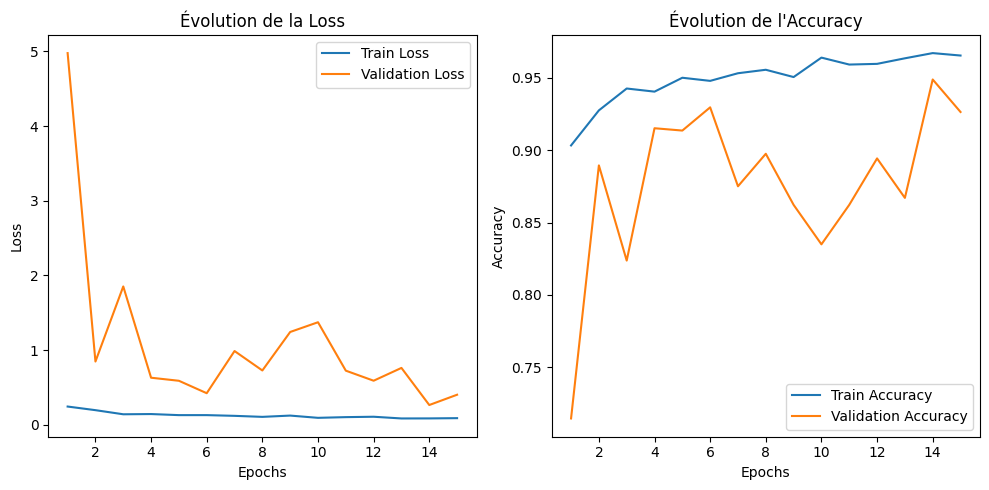

In [37]:
%pip install matplotlib

import matplotlib.pyplot as plt

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(10, 5))

# Courbes de Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Courbes d'Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label="Train Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
print("loss : " , result["loss"])
print("precision : " , result["precision"])
print("accuracy : " , result["accuracy"])
print("recall : " , result["recall"])

loss :  0.10528877377510071
precision :  0.993565022945404
accuracy :  0.9741131067276001
recall :  0.9722921848297119


In [27]:
%pip install seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 2.4 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 28.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 KB 20.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 KB 20.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [29]:
%pip install scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 28.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 KB 80.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 37.3 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step


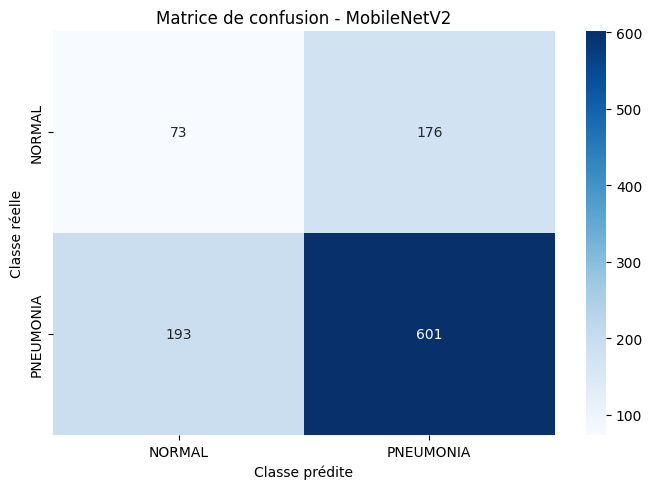

              precision    recall  f1-score   support

      NORMAL       0.27      0.29      0.28       249
   PNEUMONIA       0.77      0.76      0.77       794

    accuracy                           0.65      1043
   macro avg       0.52      0.53      0.52      1043
weighted avg       0.65      0.65      0.65      1043



In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# 1. Récupérer les vraies classes
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# 2. Prédictions du modèle
y_pred_prob = model.predict(test_ds)

# 3. Convertir les probabilités en classes (0 ou 1)
y_pred = (y_pred_prob.ravel() >= 0.5).astype(int)

# 4. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# 5. Afficher la matrice
class_names = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - MobileNetV2")
plt.tight_layout()
plt.show()

# 6. Rapport de classification
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))